### PART 1

Step 1: SET UP

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


Step 2: Load the cleaned datasets

In [2]:
# Define the cleaned data folder

cleaned_folder = Path("../data/cleaned")

# Load the cleaned datasets

customers = pd.read_csv(cleaned_folder / "olist_customers_dataset.csv")

orders = pd.read_csv(cleaned_folder / "olist_orders_dataset.csv")

order_items = pd.read_csv(cleaned_folder / "olist_order_items_dataset.csv")

order_payments = pd.read_csv(cleaned_folder / "olist_order_payments_dataset.csv")

order_reviews = pd.read_csv(cleaned_folder / "olist_order_reviews_dataset.csv")

products = pd.read_csv(cleaned_folder / "olist_products_dataset.csv")

sellers = pd.read_csv(cleaned_folder / "olist_sellers_dataset.csv")

category_translation = pd.read_csv(cleaned_folder / "product_category_name_translation.csv")

geolocation = pd.read_csv(cleaned_folder / "olist_geolocation_dataset.csv")

print("All nine cleaned datasets loaded successfully.")

All nine cleaned datasets loaded successfully.


Step 3: Confirm the datasets loaded correctly

In [3]:
# Check the dimensions of all datasets

datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Order Payments": order_payments,
    "Order Reviews": order_reviews,
    "Products": products,
    "Sellers": sellers,
    "Category Translation": category_translation,
    "Geolocation": geolocation
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Customers: (99441, 5)
Orders: (99441, 8)
Order Items: (112650, 7)
Order Payments: (103886, 5)
Order Reviews: (99224, 7)
Products: (32951, 9)
Sellers: (3095, 4)
Category Translation: (71, 2)
Geolocation: (738332, 5)


### Step 4: Prepare the date columns

Customer Purchasing Behaviour

This section examines customer purchasing patterns, including the number of customers, order frequency and repeat purchases.

In [4]:
# Convert order date columns to datetime

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

print("Order date columns converted successfully.")

orders[date_columns].dtypes

Order date columns converted successfully.


order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Step 5: Analyse customer purchasing behaviour
We will answer three questions:
1. How many unique customers placed orders?
2. How many orders were placed?
3. How many customers made repeat purchases?

5.1 Customer Order Analysis

In [5]:
# Join customers with their orders

customer_orders = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# Check the resulting dataset

print("Customer-order dataset shape:", customer_orders.shape)

customer_orders.head()

Customer-order dataset shape: (99441, 9)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6


Step 6: Calculate customer purchasing frequency


5.1 Calculate customer purchasing metrics

In [6]:
# Count the number of orders placed by each unique customer

customer_order_frequency = (
    customer_orders
    .groupby("customer_unique_id")["order_id"]
    .nunique()
    .reset_index(name="number_of_orders")
)

# Calculate overall purchasing metrics

total_customers = customer_order_frequency["customer_unique_id"].nunique()

total_orders = customer_order_frequency["number_of_orders"].sum()

single_order_customers = (
    customer_order_frequency["number_of_orders"] == 1
).sum()

repeat_customers = (
    customer_order_frequency["number_of_orders"] > 1
).sum()

repeat_purchase_rate = (
    repeat_customers / total_customers
) * 100

print("Total unique customers:", f"{total_customers:,}")
print("Total orders:", f"{total_orders:,}")
print("Customers with one order:", f"{single_order_customers:,}")
print("Customers with repeat orders:", f"{repeat_customers:,}")
print("Repeat purchase rate:", f"{repeat_purchase_rate:.2f}%")

Total unique customers: 96,096
Total orders: 99,441
Customers with one order: 93,099
Customers with repeat orders: 2,997
Repeat purchase rate: 3.12%


Step 7: Examine order frequency

5.1 Distribution of Customer Order Frequency

In [7]:
# Calculate the distribution of orders per customer

order_frequency_distribution = (
    customer_order_frequency["number_of_orders"]
    .value_counts()
    .sort_index()
    .reset_index()
)

order_frequency_distribution.columns = [
    "Number of Orders",
    "Number of Customers"
]

order_frequency_distribution["Percentage"] = (
    order_frequency_distribution["Number of Customers"]
    / total_customers * 100
)

order_frequency_distribution

,Number of Orders,Number of Customers,Percentage
0,1,93099,96.88
1,2,2745,2.86
2,3,203,0.21
3,4,30,0.03
4,5,8,0.01
5,6,6,0.01
6,7,3,0.00
7,9,1,0.00
8,17,1,0.00


Step 8: Visualise customer order frequency

5.1 Visualisation of Customer Order Frequency

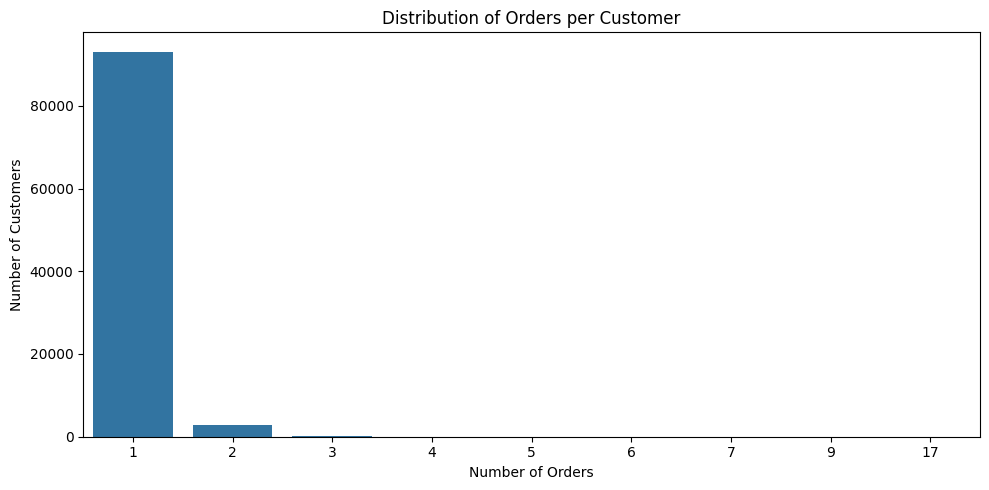

In [8]:
# Visualise customer order frequency

plt.figure(figsize=(10, 5))

sns.barplot(
    data=order_frequency_distribution,
    x="Number of Orders",
    y="Number of Customers"
)

plt.title("Distribution of Orders per Customer")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### PART 2

Our next objective is to understand how much customers spend on the platform and how that spending is distributed.

We will examine:
1. Total product sales value.
2. Total freight charges.
3. Total order value.
4. Average order value.
5. Highest and lowest order values.
6. Payment method distribution.

Customer Spending and Payment Analysis: This section examines customer spending by analysing product prices, freight charges, order values and payment methods.

Step 1: Calculate product sales and freight value

In [9]:
# Calculate product sales and freight value for each order

order_values = (
    order_items
    .groupby("order_id")
    .agg(
        product_sales=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
    .reset_index()
)

# Calculate total order value

order_values["total_order_value"] = (
    order_values["product_sales"] +
    order_values["freight_value"]
)

# Display the first five records

order_values.head()

,order_id,product_sales,freight_value,total_order_value
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,72.19
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,259.83
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,216.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,218.04


Step 2: Calculate overall customer spending metrics

In [10]:
# Calculate overall spending metrics

total_product_sales = order_values["product_sales"].sum()

total_freight = order_values["freight_value"].sum()

total_order_value = order_values["total_order_value"].sum()

average_order_value = order_values["total_order_value"].mean()

median_order_value = order_values["total_order_value"].median()

highest_order_value = order_values["total_order_value"].max()

lowest_order_value = order_values["total_order_value"].min()

print("Total product sales:", f"R${total_product_sales:,.2f}")
print("Total freight charges:", f"R${total_freight:,.2f}")
print("Total order value:", f"R${total_order_value:,.2f}")
print("Average order value:", f"R${average_order_value:,.2f}")
print("Median order value:", f"R${median_order_value:,.2f}")
print("Highest order value:", f"R${highest_order_value:,.2f}")
print("Lowest order value:", f"R${lowest_order_value:,.2f}")

Total product sales: R$13,591,643.70
Total freight charges: R$2,251,909.54
Total order value: R$15,843,553.24
Average order value: R$160.58
Median order value: R$105.29
Highest order value: R$13,664.08
Lowest order value: R$9.59


Spending Analysis Findings
- Total product sales amounted to R$13,591,643.70.
- Total freight charges amounted to R$2,251,909.54.
- Combined order value was R$15,843,553.24.
- Average order value was R$160.58, compared with a median of R$105.29.
- The difference between the average and median suggests that high-value orders influence the overall average.
- Calculations cover 98,666 orders with item records.

Step 3: Analyse payment methods

In [11]:
# Aggregate payment records by payment method

payment_analysis = (
    order_payments
    .groupby("payment_type")
    .agg(
        number_of_payments=("payment_value", "count"),
        total_payment_value=("payment_value", "sum")
    )
    .reset_index()
)

# Calculate each payment method's share of total payment value

total_payments_value = payment_analysis["total_payment_value"].sum()

payment_analysis["percentage_of_total"] = (
    payment_analysis["total_payment_value"]
    / total_payments_value * 100
)

# Sort by highest payment value

payment_analysis = payment_analysis.sort_values(
    by="total_payment_value",
    ascending=False
)

payment_analysis

,payment_type,number_of_payments,total_payment_value,percentage_of_total
1,credit_card,76795,"12,542,084.19",78.34
0,boleto,19784,"2,869,361.27",17.92
4,voucher,5775,"379,436.87",2.37
2,debit_card,1529,"217,989.79",1.36
3,not_defined,3,0.00,0.00


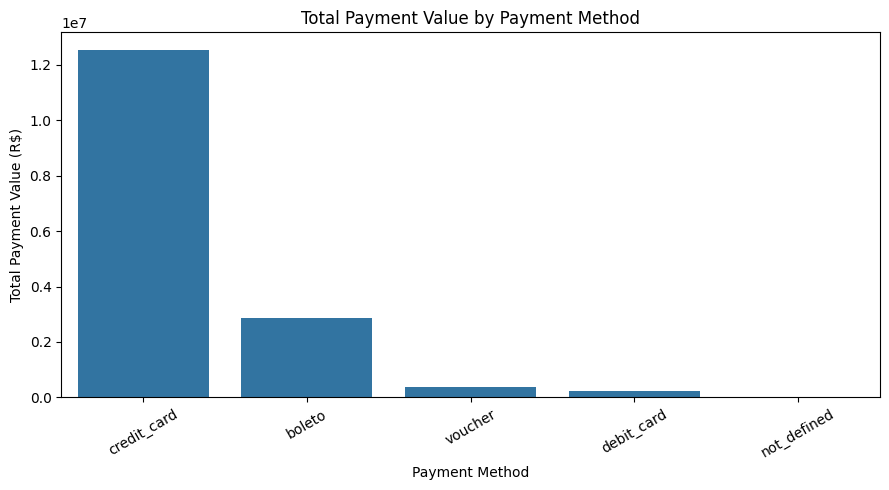

In [12]:
# Visualise total payment value by payment method

plt.figure(figsize=(9, 5))

sns.barplot(
    data=payment_analysis,
    x="payment_type",
    y="total_payment_value"
)

plt.title("Total Payment Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Payment Value (R$)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

PART 3

Our objective is to establish which product categories generate the most revenue and which categories have the highest sales quantities.

We will use:
- order_items — product prices and quantities purchased.
- products — product IDs and original category names.
- category_translation — English translations of category names.

Step 1: Product Category Performance Analysis 

In [13]:
# Merge order items with product information

category_sales = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# Add English product category names

category_sales = category_sales.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

# Inspect the merged dataset

print("Dataset shape:", category_sales.shape)

category_sales.head()

Dataset shape: (112650, 9)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,garden_tools


: Check category names and translations

In [14]:
# Check missing category names and English translations

print("Missing original category names:",
      category_sales["product_category_name"].isna().sum())

print("Missing English category translations:",
      category_sales["product_category_name_english"].isna().sum())

# Display categories without English translations

category_sales.loc[
    category_sales["product_category_name_english"].isna(),
    "product_category_name"
].value_counts(dropna=False)

Missing original category names: 1603
Missing English category translations: 1627


product_category_name
NaN                                              1603
portateis_cozinha_e_preparadores_de_alimentos      15
pc_gamer                                            9
Name: count, dtype: int64

: Apply the two known translations

In [15]:
# Apply analyst-supplied translations for the two unmatched categories

category_mapping = {
    "portateis_cozinha_e_preparadores_de_alimentos":
        "Portable Kitchen Appliances and Food Processors",

    "pc_gamer":
        "PC Gaming"
}

category_sales["product_category_name_english"] = (
    category_sales["product_category_name_english"]
    .fillna(category_sales["product_category_name"].map(category_mapping))
)

# Label genuinely missing categories

category_sales["product_category_name_english"] = (
    category_sales["product_category_name_english"]
    .fillna("Unknown Category")
)

# Verify the results

print(
    "Remaining missing English category names:",
    category_sales["product_category_name_english"].isna().sum()
)

category_sales["product_category_name_english"].value_counts().head(10)

Remaining missing English category names: 0


product_category_name_english
bed_bath_table           11115
health_beauty             9670
sports_leisure            8641
furniture_decor           8334
computers_accessories     7827
housewares                6964
watches_gifts             5991
telephony                 4545
garden_tools              4347
auto                      4235
Name: count, dtype: int64

Step 2: Calculate category revenue and sales quantity

Now we want to answer two questions:
1. Which product categories generate the highest revenue?
2. Which product categories have the highest sales quantities?

In [18]:
# Aggregate sales performance by product category

category_performance = (
    category_sales
    .groupby("product_category_name_english")
    .agg(
        number_of_items=("order_item_id", "count"),
        total_revenue=("price", "sum"),
        average_item_price=("price", "mean")
    )
    .reset_index()
)

# Calculate each category's percentage contribution to total revenue

total_category_revenue = category_performance["total_revenue"].sum()

category_performance["revenue_percentage"] = (
    category_performance["total_revenue"]
    / total_category_revenue * 100
)

# Sort by highest revenue

category_performance = category_performance.sort_values(
    by="total_revenue",
    ascending=False
)

category_performance.head(15)

,product_category_name_english,number_of_items,total_revenue,average_item_price,revenue_percentage
46,health_beauty,9670,"1,258,681.34",130.16,9.26
73,watches_gifts,5991,"1,205,005.68",201.14,8.87
10,bed_bath_table,11115,"1,036,988.68",93.30,7.63
68,sports_leisure,8641,"988,048.97",114.34,7.27
18,computers_accessories,7827,"911,954.32",116.51,6.71
42,furniture_decor,8334,"729,762.49",87.56,5.37
23,cool_stuff,3796,"635,290.85",167.36,4.67
52,housewares,6964,"632,248.66",90.79,4.65
8,auto,4235,"592,720.11",139.96,4.36
45,garden_tools,4347,"485,256.46",111.63,3.57


: Visualize the top five revenue-generating categories

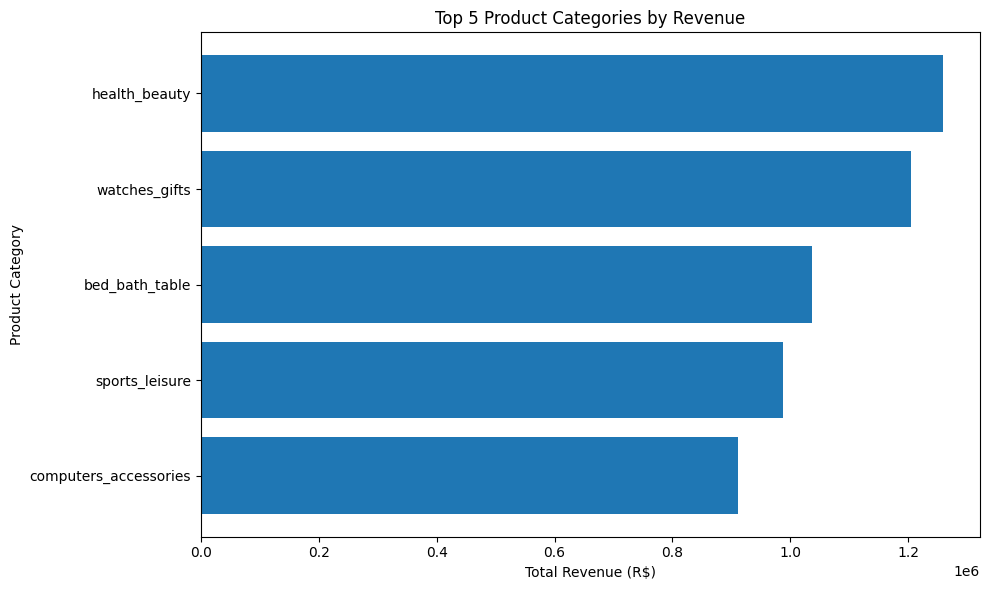

In [19]:
# Select the top five categories by revenue

top_5_categories = category_performance.head(5).sort_values(
    by="total_revenue",
    ascending=True
)

# Create horizontal bar chart

plt.figure(figsize=(10, 6))

plt.barh(
    top_5_categories["product_category_name_english"],
    top_5_categories["total_revenue"]
)

plt.title("Top 5 Product Categories by Revenue")
plt.xlabel("Total Revenue (R$)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

: Visualize the top five categories by item quantity

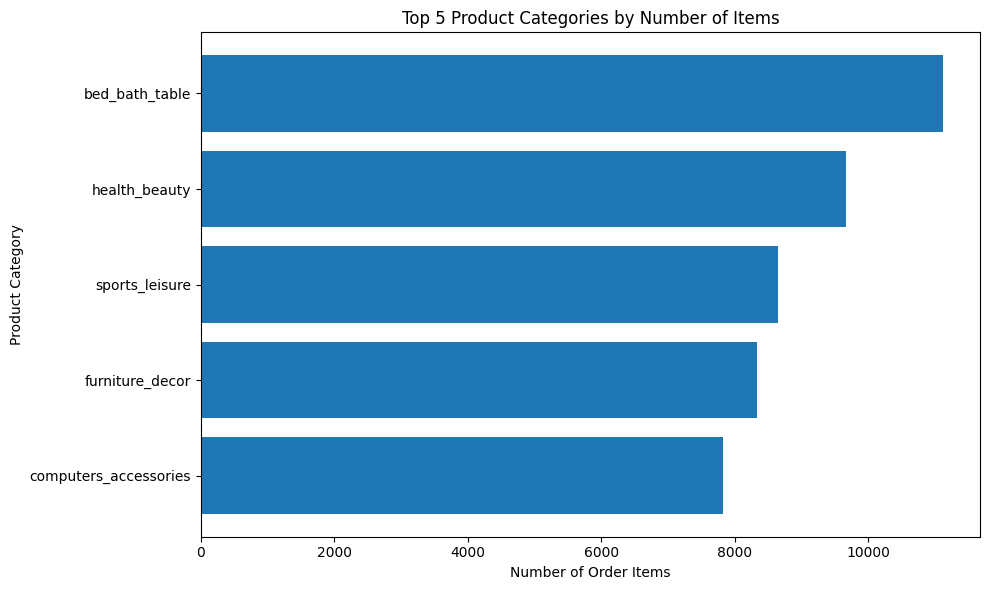

In [20]:
# Select the top five categories by number of items

top_5_items = category_performance.sort_values(
    by="number_of_items",
    ascending=False
).head(5).sort_values(
    by="number_of_items",
    ascending=True
)

# Create horizontal bar chart

plt.figure(figsize=(10, 6))

plt.barh(
    top_5_items["product_category_name_english"],
    top_5_items["number_of_items"]
)

plt.title("Top 5 Product Categories by Number of Items")
plt.xlabel("Number of Order Items")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

### Product Category Performance – Key Findings

- **Health & Beauty** generated the highest product revenue at R$1,258,681.34, contributing 9.26% of total product sales.
- **Watches & Gifts** ranked second in revenue at R$1,205,005.68, despite having fewer order-item records than the other leading categories.
- **Bed, Bath & Table** recorded the highest number of order items at 11,115 but ranked third in revenue.
- The results show that high sales volume does not necessarily translate into the highest revenue. Differences in average product prices contribute to category revenue differences.

**Analytical note:** Revenue represents the sum of product prices and excludes freight charges. Sales quantity is measured using order-item records, not distinct orders or verified physical units.

Step 3. Delivery Performance and Customer Reviews

This section examines actual delivery times against estimated delivery dates and investigates whether late deliveries are associated with lower customer review scores.

: Check review records per order

In [21]:
# Check whether any order has more than one review record
review_counts = (
    order_reviews.groupby("order_id")
    .size()
    .reset_index(name="review_count")
)

print("Total review records:", len(order_reviews))
print("Unique orders with reviews:", order_reviews["order_id"].nunique())
print("Orders with multiple review records:",
      (review_counts["review_count"] > 1).sum())

print("\nDistribution of review records per order:")
print(review_counts["review_count"].value_counts().sort_index())

Total review records: 99224
Unique orders with reviews: 98673
Orders with multiple review records: 547

Distribution of review records per order:
review_count
1    98126
2      543
3        4
Name: count, dtype: int64


: Prepare one review score per order

In [22]:
# Calculate the average review score for each order
order_review_summary = (
    order_reviews.groupby("order_id")
    .agg(
        average_review_score=("review_score", "mean"),
        number_of_reviews=("review_score", "count")
    )
    .reset_index()
)

# Confirm that each order now appears only once
print("Review summary rows:", len(order_review_summary))
print("Unique orders:", order_review_summary["order_id"].nunique())
print(
    "Duplicate order IDs:",
    order_review_summary["order_id"].duplicated().sum()
)

Review summary rows: 98673
Unique orders: 98673
Duplicate order IDs: 0


: Join reviews to delivery dates

In [23]:
# Select the delivery-related columns from orders
delivery_columns = [
    "order_id",
    "order_status",
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Join the order-level review summary to delivery information
delivery_reviews = orders[delivery_columns].merge(
    order_review_summary,
    on="order_id",
    how="inner"
)

print("Joined dataset shape:", delivery_reviews.shape)
print("\nMissing values in delivery-related columns:")
print(
    delivery_reviews[
        [
            "order_delivered_customer_date",
            "order_estimated_delivery_date",
            "average_review_score"
        ]
    ].isna().sum()
)

print("\nOrder status distribution:")
print(delivery_reviews["order_status"].value_counts())

Joined dataset shape: (98673, 7)

Missing values in delivery-related columns:
order_delivered_customer_date    2843
order_estimated_delivery_date       0
average_review_score                0
dtype: int64

Order status distribution:
order_status
delivered      95832
shipped         1032
canceled         605
unavailable      595
invoiced         309
processing       295
created            3
approved           2
Name: count, dtype: int64


: Calculate delivery duration and classify delivery performance

In [24]:
# Keep only delivered orders with valid actual and estimated delivery dates
delivered_orders = delivery_reviews[
    (delivery_reviews["order_status"] == "delivered") &
    (delivery_reviews["order_delivered_customer_date"].notna()) &
    (delivery_reviews["order_estimated_delivery_date"].notna())
].copy()

# Calculate actual delivery duration in days
delivered_orders["delivery_days"] = (
    delivered_orders["order_delivered_customer_date"] -
    delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Classify delivery performance
delivered_orders["delivery_performance"] = np.where(
    delivered_orders["order_delivered_customer_date"] >
    delivered_orders["order_estimated_delivery_date"],
    "Late",
    "On time"
)

# Display the number of records available for analysis
print("Delivered orders available for analysis:", len(delivered_orders))

print("\nDelivery performance distribution:")
print(delivered_orders["delivery_performance"].value_counts())

print("\nDelivery performance percentages:")
print(
    delivered_orders["delivery_performance"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Delivered orders available for analysis: 95824

Delivery performance distribution:
delivery_performance
On time    88163
Late        7661
Name: count, dtype: int64

Delivery performance percentages:
delivery_performance
On time   92.01
Late       7.99
Name: proportion, dtype: float64


: Compare customer review scores

In [25]:
# Compare review scores by delivery performance
delivery_review_analysis = (
    delivered_orders
    .groupby("delivery_performance")
    .agg(
        number_of_orders=("order_id", "nunique"),
        average_review_score=("average_review_score", "mean"),
        median_review_score=("average_review_score", "median")
    )
    .reset_index()
)

delivery_review_analysis["average_review_score"] = (
    delivery_review_analysis["average_review_score"].round(2)
)

print(delivery_review_analysis)

  delivery_performance  number_of_orders  average_review_score  \
0                 Late              7661                  2.57   
1              On time             88163                  4.29   

   median_review_score  
0                 2.00  
1                 5.00  


: Visualise the relationship

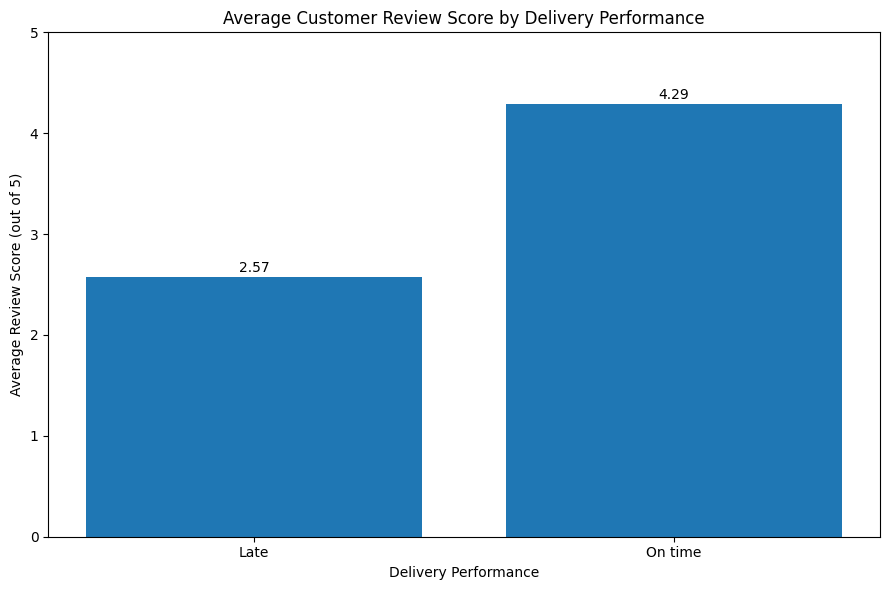

In [26]:
# Sort delivery categories for consistent chart presentation
review_chart_data = delivery_review_analysis.sort_values(
    by="average_review_score",
    ascending=True
)

plt.figure(figsize=(9, 6))

bars = plt.bar(
    review_chart_data["delivery_performance"],
    review_chart_data["average_review_score"]
)

plt.title("Average Customer Review Score by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Average Review Score (out of 5)")
plt.ylim(0, 5)

# Display values above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.05,
        f"{height:.2f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "../reports/figures/average_review_score_by_delivery_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Delivery Performance and Customer Reviews – Key Findings

- Of the 95,824 delivered orders with complete delivery dates and customer reviews, 88,163 (92.01%) arrived on time, while 7,661 (7.99%) arrived late.
- On-time deliveries received an average customer review score of 4.29 out of 5.
- Late deliveries received a considerably lower average review score of 2.57 out of 5.
- The 1.72-point difference suggests that delivery delays are strongly associated with lower customer satisfaction.

Analytical note: Delivery performance was classified by comparing the actual customer delivery date with the estimated delivery date. Orders without actual delivery dates were excluded. Multiple review records for an order were combined using their average score so that each order contributed only one observation. The results show an association, not proof of causation.